# 02 — Publication-Quality Visualizations

This notebook creates polished charts suitable for a portfolio or presentation:

1. **Conversion rate comparison** with error bars showing the 95% confidence interval
2. **Conversion rate by hour** to identify optimal ad timing

These charts go beyond basic EDA — they communicate statistical uncertainty, which is what distinguishes a data analyst from someone who just makes bar charts.

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
import matplotlib.pyplot as plt
import seaborn as sns

# Clean, professional style
sns.set_style("whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "font.size": 12,
    "axes.titlesize": 15,
    "axes.labelsize": 13,
})

In [2]:
# Load data
df = pd.read_csv("../data/raw/marketing_AB.csv")
print(f"Loaded {len(df):,} rows")

Loaded 588,101 rows


## Chart 1: Conversion Rate by Group with 95% Confidence Interval Error Bars

### Why error bars matter

A bar chart without error bars is incomplete — it shows the *point estimate* but hides how much uncertainty surrounds that estimate. The 95% CI tells the reader: "We are 95% confident that the *true* conversion rate for this group falls within this range."

### How we compute the CI for a proportion

For a proportion $p$ estimated from $n$ observations, the 95% CI is:

$$p \pm z_{0.975} \times \sqrt{\frac{p(1-p)}{n}}$$

where $z_{0.975} = 1.96$ for a 95% confidence level.

In [3]:
def proportion_ci(data, confidence=0.95):
    """
    Compute the confidence interval for a binary proportion.
    
    Uses the Wald interval (normal approximation), which is valid
    for large samples (n > 30 and np > 5 and n(1-p) > 5).
    
    Returns: (proportion, margin_of_error)
    """
    n = len(data)
    p = data.mean()  # proportion of True values
    z = stats.norm.ppf((1 + confidence) / 2)  # 1.96 for 95%
    se = np.sqrt(p * (1 - p) / n)  # standard error of a proportion
    margin = z * se
    return p, margin


# Calculate conversion rate and CI for each group
groups = ["ad", "psa"]
rates = []
margins = []

for group in groups:
    group_data = df[df["test group"] == group]["converted"]
    p, m = proportion_ci(group_data)
    rates.append(p * 100)       # Convert to percentage
    margins.append(m * 100)     # Convert to percentage
    print(f"{group.upper()}: {p:.4%} ± {m:.4%}  (95% CI: [{(p-m):.4%}, {(p+m):.4%}])")

AD: 2.5547% ± 0.0412%  (95% CI: [2.5135%, 2.5958%])
PSA: 1.7854% ± 0.1692%  (95% CI: [1.6162%, 1.9546%])


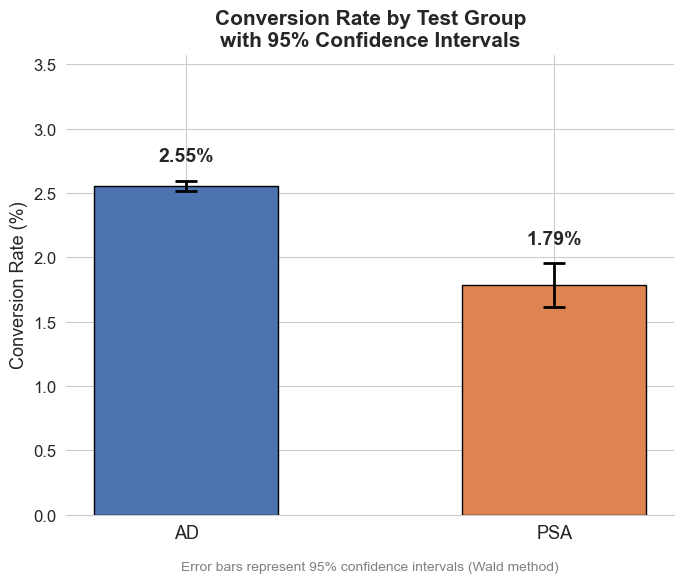

Saved: conversion_rate_comparison.png


In [4]:
# ── CHART 1: Conversion Rate with Error Bars ──────────────────────────

fig, ax = plt.subplots(figsize=(7, 6))

colors = ["#4C72B0", "#DD8452"]
x_pos = np.arange(len(groups))

bars = ax.bar(
    x_pos,
    rates,
    yerr=margins,  # Error bars = margin of error from the CI
    capsize=8,     # Size of the error bar caps
    color=colors,
    edgecolor="black",
    width=0.5,
    error_kw={"linewidth": 2, "capthick": 2},  # Make error bars visible
)

# Labels on bars
for bar, rate, margin in zip(bars, rates, margins):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + margin + 0.15,
        f"{rate:.2f}%",
        ha="center",
        fontweight="bold",
        fontsize=14,
    )

ax.set_xticks(x_pos)
ax.set_xticklabels([g.upper() for g in groups], fontsize=13)
ax.set_ylabel("Conversion Rate (%)")
ax.set_title(
    "Conversion Rate by Test Group\nwith 95% Confidence Intervals",
    fontsize=15,
    fontweight="bold",
)
ax.set_ylim(0, max(rates) * 1.4)

# Add a footnote explaining the error bars
ax.annotate(
    "Error bars represent 95% confidence intervals (Wald method)",
    xy=(0.5, -0.12),
    xycoords="axes fraction",
    ha="center",
    fontsize=10,
    color="gray",
)

sns.despine(left=True)
plt.tight_layout()
plt.savefig("../conversion_rate_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: conversion_rate_comparison.png")

## Chart 2: Conversion Rate by Hour of Day

Even if the overall campaign effect is small, there may be specific hours where ads are particularly effective. This analysis can drive a **targeting recommendation** — e.g., "show ads primarily between 6 PM and 10 PM for maximum impact."

In [5]:
# Calculate conversion rate by hour, split by test group
hourly = (
    df.groupby(["most ads hour", "test group"])["converted"]
    .mean()
    .unstack()
    * 100
)

# Also calculate overall conversion rate by hour
hourly_overall = df.groupby("most ads hour")["converted"].mean() * 100

hourly.head()

test group,ad,psa
most ads hour,,
0,1.921266,0.000000
1,1.343445,0.000000
2,0.756988,0.000000
3,1.042471,1.123596
4,1.585014,0.000000


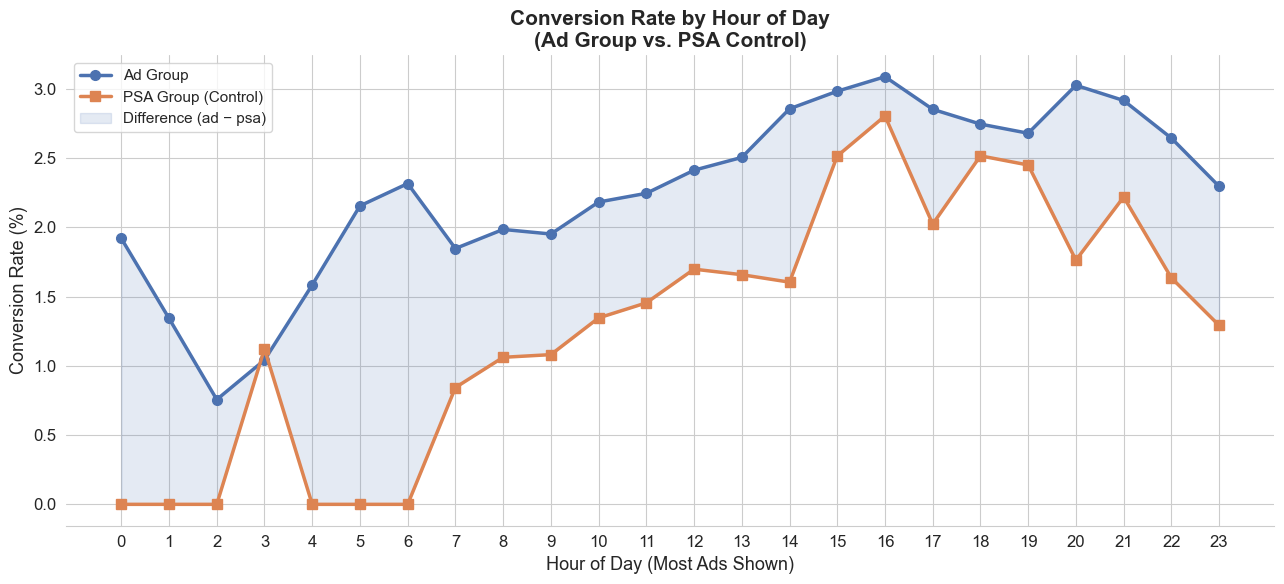

Saved: conversion_by_hour.png


In [6]:
# ── CHART 2: Conversion Rate by Hour ─────────────────────────────────

fig, ax = plt.subplots(figsize=(13, 6))

# Plot each group as a line
if "ad" in hourly.columns:
    ax.plot(
        hourly.index, hourly["ad"],
        marker="o", linewidth=2.5, markersize=7,
        color="#4C72B0", label="Ad Group",
    )
if "psa" in hourly.columns:
    ax.plot(
        hourly.index, hourly["psa"],
        marker="s", linewidth=2.5, markersize=7,
        color="#DD8452", label="PSA Group (Control)",
    )

# Shade the area between the two lines to highlight the gap
if "ad" in hourly.columns and "psa" in hourly.columns:
    ax.fill_between(
        hourly.index,
        hourly["ad"],
        hourly["psa"],
        alpha=0.15,
        color="#4C72B0",
        label="Difference (ad − psa)",
    )

ax.set_title(
    "Conversion Rate by Hour of Day\n(Ad Group vs. PSA Control)",
    fontsize=15,
    fontweight="bold",
)
ax.set_xlabel("Hour of Day (Most Ads Shown)")
ax.set_ylabel("Conversion Rate (%)")
ax.set_xticks(range(0, 24))
ax.legend(loc="upper left", fontsize=11)

sns.despine(left=True)
plt.tight_layout()
plt.savefig("../conversion_by_hour.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: conversion_by_hour.png")

## Chart 3: Conversion Rate by Total Ads Exposure (Binned)

Does seeing *more* ads lead to higher conversion? This is a dose-response question.

C:\Users\simba\AppData\Local\Temp\ipykernel_19384\40630346.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(["ads_bin", "test group"])["converted"]


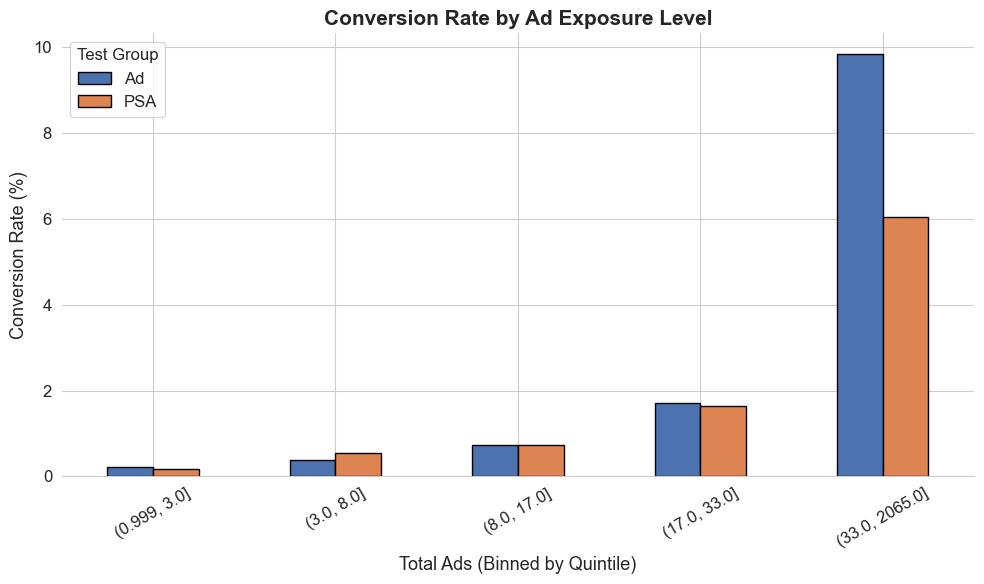

Saved: conversion_by_exposure.png


In [7]:
# Bin 'total ads' into quantile-based groups for cleaner visualization
df["ads_bin"] = pd.qcut(df["total ads"], q=5, duplicates="drop")

binned_conversion = (
    df.groupby(["ads_bin", "test group"])["converted"]
    .mean()
    .unstack()
    * 100
)

fig, ax = plt.subplots(figsize=(10, 6))

binned_conversion.plot(kind="bar", ax=ax, color=["#4C72B0", "#DD8452"], edgecolor="black")
ax.set_title(
    "Conversion Rate by Ad Exposure Level",
    fontsize=15,
    fontweight="bold",
)
ax.set_xlabel("Total Ads (Binned by Quintile)")
ax.set_ylabel("Conversion Rate (%)")
ax.legend(title="Test Group", labels=["Ad", "PSA"])
plt.xticks(rotation=30)

sns.despine(left=True)
plt.tight_layout()
plt.savefig("../conversion_by_exposure.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: conversion_by_exposure.png")

## Summary

These visualizations tell the story:

1. **Chart 1** answers: "Is there a meaningful difference in conversion rates?" — and the error bars show whether the difference is within the margin of noise.
2. **Chart 2** answers: "When should we show ads?" — identifying peak-conversion hours can optimize ad scheduling.
3. **Chart 3** answers: "Does more exposure help?" — understanding the dose-response relationship prevents wasted impressions.

For the formal statistical test (chi-square), see `scripts/ab_test.py`.